In [1]:
import os
import torch
import pandas as pd
import scanpy as sc
from sklearn import metrics
import multiprocessing as mp
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from MVGRLST import MVGRLST

In [3]:
import torch
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# 读入数据

In [4]:
n_clusters = 5
dataset = '151672'

In [5]:
# read data
file_fold = '/root/autodl-tmp/Data/DLPFC/' + str(dataset)  #please replace 'file_fold' with the download path
adata = sc.read_visium(file_fold, count_file='filtered_feature_bc_matrix.h5', load_images=True)
adata.var_names_make_unique()

Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


# 运行MVGRLST模型

In [ ]:
# define model
model = MVGRLST.MVGRLST(adata, device=device,random_seed=2023,alpha = 1,
        beta =4)
# train model
adata = model.train()

# Mclust 聚类

In [7]:
# add ground_truth
df_meta = pd.read_csv(file_fold + '/metadata.tsv', sep='\t')
df_meta_layer = df_meta['layer_guess']
adata.obs['ground_truth'] = df_meta_layer.values

In [8]:
# set radius to specify the number of neighbors considered during refinement
radius = 50
tool = 'mclust' # mclust, leiden, and louvain

# clustering
from MVGRLST.utils import clustering

if tool == 'mclust':
   clustering(adata, n_clusters, radius=radius, method=tool, refinement=True) # For DLPFC dataset, we use optional refinement step.
elif tool in ['leiden', 'louvain']:
   clustering(adata, n_clusters, radius=radius, method=tool, start=0.7, end=1.0, increment=0.05, refinement=True)

R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.1.1
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%


# 可视化

In [13]:
# 可选：一次性计算多个指标
from sklearn import metrics
# filter out NA nodes
adata = adata[~pd.isnull(adata.obs['ground_truth'])]
labels_true = adata.obs['DVGRL_refined']
#labels_true = adata.obs['domain']
labels_pred = adata.obs['ground_truth']

scores = {
    'ARI': metrics.adjusted_rand_score(labels_true, labels_pred),
    'AMI': metrics.adjusted_mutual_info_score(labels_true, labels_pred),
    'NMI': metrics.normalized_mutual_info_score(labels_true, labels_pred),
    'FMI': metrics.fowlkes_mallows_score(labels_true, labels_pred),
    'homogeneity':metrics.homogeneity_score(labels_true, labels_pred),
    'completeness':metrics.completeness_score(labels_true, labels_pred),
    'v_measure':metrics.v_measure_score(labels_true, labels_pred)
}

# 保存到 adata.uns
adata.uns['clustering_metrics'] = scores
print(dataset)
# 打印所有指标
print("\n=== Clustering Metrics ===")
for metric, value in scores.items():
    print(f'{metric}: {value:.4f}')

Trying to set attribute `._uns` of view, copying.


151672

=== Clustering Metrics ===
ARI: 0.7958
AMI: 0.7639
NMI: 0.7642
FMI: 0.8569
homogeneity: 0.8149
completeness: 0.7195
v_measure: 0.7642


In [15]:
ARI = metrics.adjusted_rand_score(adata.obs['domain'], adata.obs['ground_truth'])
adata.uns['ARI'] = ARI

<Figure size 600x600 with 0 Axes>

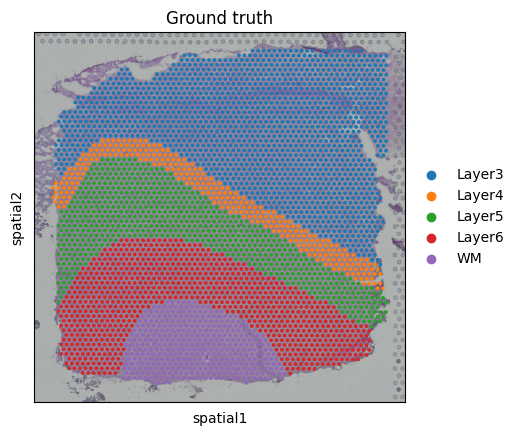

In [17]:
# plotting spatial clustering result
import matplotlib.pyplot as plt
# Create a figure explicitly before plotting
fig = plt.figure(figsize=(6, 6))  
sc.pl.spatial(adata,
              img_key="hires",
              color=["ground_truth"],
              title=["Ground truth"],
              show=False)
# Save as EPS in the specified directory
output_dir = '/root/autodl-tmp/result/DLPFC/'
output_path = f"{output_dir}/{dataset}raw.pdf"
plt.savefig(output_path, format='pdf', bbox_inches='tight') # bbox_inches='tight' prevents cropping
plt.show()
plt.close()

... storing 'DVGRL_refined' as categorical


<Figure size 600x600 with 0 Axes>

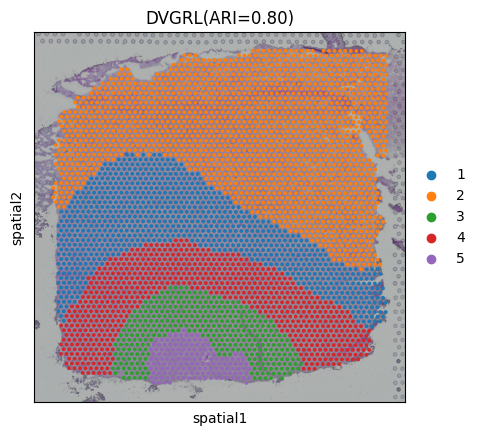

In [16]:
# plotting spatial clustering result
import matplotlib.pyplot as plt
# Create a figure explicitly before plotting
fig = plt.figure(figsize=(6, 6))  
sc.pl.spatial(adata,
              img_key="hires",
              color=[ "domain"],
              title=["DVGRL(ARI=%.2f)"%ARI],
              show=False)
# Save as EPS in the specified directory
output_dir = '/root/autodl-tmp/result/DLPFC/'
output_path = f"{output_dir}/{dataset}DVGRL.pdf"
plt.savefig(output_path, format='pdf', bbox_inches='tight') # bbox_inches='tight' prevents cropping
plt.show()
plt.close()